# Import and Functions

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import math
import sys
import ast
import os
import matplotlib.patheffects as path_effects
sys.path.append('../')
from utils.Evaluation.calculate_metrics import calculate_scores
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.patheffects as path_effects
sns.set_style(style='whitegrid')  # Better background
from collections import defaultdict, Counter
from typing import List, Tuple, Dict

In [2]:
error_categories_with_errors={
    'Schema Errors':[
    'Neo.ClientNotification.Statement.UnknownLabelWarning',
    'Neo.ClientNotification.Statement.UnknownRelationshipTypeWarning',
    'UnknownPathWarning',
    'WrongDirectionPathWarning',
    'VariableLengthPathWarning',
    'WrongDirectionPath&VariableLengthPathWarning'
],
 'Properties Errors':[
    'Neo.ClientNotification.Statement.UnknownPropertyKeyWarning',
    'InvalidPropertyAccessByLabelWarning'
],
'Syntax Errors':['Neo.ClientError.Statement.SyntaxError',
'Neo.DatabaseError.Statement.ExecutionFailed',
'Neo.ClientError.Statement.SyntaxError',
'Neo.ClientNotification.Statement.ParameterNotProvided',
'Neo.ClientNotification.Statement.UnsatisfiableRelationshipTypeExpression',
'Neo.ClientError.Statement.ArithmeticError',
'ConflictingVariablesError',
'Neo.ClientError.Procedure.ProcedureNotFound']
}

error_to_cat = {err: cat for cat, errs in error_categories_with_errors.items() for err in errs}

In [3]:
def extract_dfs(df):

    kg_valid_queries_df = df[df['is_KG_Valid_correct']==True].reset_index(drop=True)
    unavailable_output_df = df[df['answer']=="I couldn't find any relevant information in the database"].reset_index(drop=True)
    kg_valid_queries_with_full_schema_df = df[df['is_KG_Valid_correct_with_full_schema']==True].reset_index(drop=True)
    kg_valid_queries_with_filtered_schema_df = df[(df['is_KG_Valid_correct_with_full_schema']==False) & (df['is_KG_Valid_correct']==True)].reset_index(drop=True)

    return kg_valid_queries_df,unavailable_output_df,kg_valid_queries_with_full_schema_df,kg_valid_queries_with_filtered_schema_df

def extract_params(model_name):
    import re
    match = re.search(r'([\d.]+)[bB]', model_name)
    if match:
        return float(match.group(1))
    return 1000  # Default if no match

def count_tries(row):
    path = row['path']
    cypher_corrector_freq = path.count('cypher_corrector')
    if 'schema_retriever' in path:
        # KG valid with full schema
        if 'output_generator' in path:
            count = cypher_corrector_freq - 5
        # Unvailable Output
        else:
            count = None
    # KG Valid with filtered schema
    else:
        count = cypher_corrector_freq
    return count

def remove_duplicates(row):
    unique_elements =row[:len(row) // 2]
    return unique_elements

def extract_error_types_as_lists(nested_list):
    return [[s.split(':')[0].strip() for s in sublist] for sublist in nested_list]

def extract_error_types(nested_list):
    return [s.split(':')[0] for sublist in nested_list for s in sublist]

# Function to transform list of lists to list of lists of (category, error) tuples
def map_errors_codes_to_categories(nested_error_list):
    if not nested_error_list:
        return [[('No errors', None)]]
    result = []
    for inner_list in nested_error_list:
        if not inner_list:
            result.append([('No errors', None)])
        else:
            result.append([(error_to_cat.get(err, 'Unknown'), err) for err in inner_list])
    return result

def map_errors_to_categories(nested_error_list):
    if not nested_error_list:
        return [[('No errors', None)]]
    result = []
    for inner_list in nested_error_list:
        if not inner_list:
            result.append([('No errors', None)])
        else:
            result.append([(error_to_cat.get(err.split(':')[0].strip(), 'Unknown'), err) for err in inner_list])
    return result

def calculate_dicts(source_directory,extended=True):
    dict_with_models={}
    for name in os.listdir(source_directory):
        folder_path = os.path.join(source_directory, name)
        if os.path.isdir(folder_path):
            # “name” is an immediate folder
            print(f"Entering folder: {folder_path}")
            # do your work here, e.g. list files inside:
            for file in os.listdir(folder_path):
                file_path = os.path.join(folder_path, file)
                if file.endswith('.xlsx'):
                    df = pd.read_excel(file_path)
                    df = df[df['Original_KG_Valid']==True].reset_index(drop=True)
                    if extended:
                        list_columns = ['path','cypher_errors_history', 'cypher_errors']
                        for col in list_columns:
                            df[col] = df[col].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) else x)
                        
                        # Extract error types from cypher_errors_history
                        df['cypher_errors_history'] = df['cypher_errors_history'].apply(remove_duplicates)
                        df['flattened_cypher_errors_history'] = df['cypher_errors_history'].apply(extract_error_types)
                        df['cypher_errors_codes_history'] = df['cypher_errors_history'].apply(extract_error_types_as_lists)
                        df['cypher_errors_codes_with_categories'] = df['cypher_errors_codes_history'].apply(map_errors_codes_to_categories)
                        df['cypher_errors_with_categories'] = df['cypher_errors_history'].apply(map_errors_to_categories)
                    # else:
                    #     df['is_KG_Valid_correct'] = (
                    #                                     (df['Schema Valid'] == 1) &
                    #                                     ((df['Properties Valid'] == 1) | df['Properties Valid'].isna()) &
                    #                                     (df['Syntax Valid'] == True)
                    #                                 )
                    #     df['is_KG_Valid_correct'] = df['is_KG_Valid_correct'].astype(bool)

                    model_name = file.split('.')[0]
                    model_name = model_name.replace('openrouter_', '')
                    model_name = model_name.replace('_local', '')
                    dict_with_models[model_name] = df        

    return dict_with_models

# Calculate Melted and Pivot DFs across Models

Define the models mapping and the dataset that we want to evaluate

We end up with two dfs 
 - one melted df
 - one pivoted df

In [4]:
# Combine all metric data into one list
models_mapping = {
    'gpt_4o':'gpt4o', 
    'llama3_2_3b':'Llama-3.2-3B-Instruct',
    'finetuned_azzedde_llama3_1_8b':'Finetuned-AzzedeLlama-3.1-8b',
    'llama3_1_8b':'Llama-3.1-8B-Instruct',
    'gemma2_9b':'gemma-2-9b-it',
    'finetuned_gemma2_9b': 'Finetuned-gemma-2-9b-it'
}

dataset = 'BenchmarkDataset2025'

In [5]:
extended_dfs_dict = calculate_dicts("./extended_workflow/Outputs_Evaluation/"+dataset,extended=True)
extended_dfs_dict = dict(sorted(extended_dfs_dict.items(), key=lambda item: extract_params(item[0])))

Entering folder: ./extended_workflow/Outputs_Evaluation/BenchmarkDataset2025/finetuned_gemma2_9b_local
Entering folder: ./extended_workflow/Outputs_Evaluation/BenchmarkDataset2025/llama3_2_3b
Entering folder: ./extended_workflow/Outputs_Evaluation/BenchmarkDataset2025/gemma2_9b
Entering folder: ./extended_workflow/Outputs_Evaluation/BenchmarkDataset2025/finetuned_azzedde_llama3_1_8b
Entering folder: ./extended_workflow/Outputs_Evaluation/BenchmarkDataset2025/llama3_1_8b
Entering folder: ./extended_workflow/Outputs_Evaluation/BenchmarkDataset2025/gpt_4o


In [6]:
all_dfs =[]
for model_name, df in extended_dfs_dict.items():
    # Iteration and Group
    df['Iteration'] = df.apply(count_tries, axis=1)
    df['Group'] = np.where(
    (df['is_KG_Valid_correct_with_full_schema'] == False) & (df['is_KG_Valid_correct'] == True),
    'KG Valid Queries (Filtered Schema)',
    np.where(df['is_KG_Valid_correct_with_full_schema'] == True,'KG Valid Queries (Full Schema)' , 'Unavailable Output')
    )
    # GroupBy
    grouped_df = df.groupby(['Group','Iteration'], dropna=False).size().reset_index(name='Value')
    grouped_df['Model'] = models_mapping[model_name]
    all_dfs.append(grouped_df)

all_df = pd.concat(all_dfs, ignore_index=True)


In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

metrics = ['PersistedCount', 'NewCount', 'DeltaCount']
categories = df['Category'].unique()

fig, axes = plt.subplots(1, 3, figsize=(20, 6), sharex=True)

for ax, metric in zip(axes, metrics):
    for cat in categories:
        subset = df[df['Category'] == cat]
        sns.boxplot(x='Iteration', y=metric, data=subset, ax=ax, 
                    showcaps=True, boxprops={'facecolor':'lightblue'}, 
                    whiskerprops={'color':'blue'}, 
                    showfliers=False,  # Hide outliers for clarity
                    linewidth=1)
    ax.set_title(f'{metric} Distribution per Iteration')
    ax.set_ylabel(metric)
    ax.set_xlabel('Iteration')

plt.tight_layout()
plt.show()


KeyError: 'Category'

# Iterations

In [14]:
df

,Group,Iteration,Value,Model
0,KG Valid Queries (Filtered Schema),0.0,803,Llama-3.2-3B-Instruct
1,KG Valid Queries (Filtered Schema),1.0,286,Llama-3.2-3B-Instruct
2,KG Valid Queries (Filtered Schema),2.0,104,Llama-3.2-3B-Instruct
3,KG Valid Queries (Filtered Schema),3.0,61,Llama-3.2-3B-Instruct
4,KG Valid Queries (Filtered Schema),4.0,46,Llama-3.2-3B-Instruct
5,KG Valid Queries (Filtered Schema),5.0,32,Llama-3.2-3B-Instruct
6,KG Valid Queries (Full Schema),0.0,107,Llama-3.2-3B-Instruct
7,KG Valid Queries (Full Schema),1.0,70,Llama-3.2-3B-Instruct
8,KG Valid Queries (Full Schema),2.0,36,Llama-3.2-3B-Instruct
9,KG Valid Queries (Full Schema),3.0,23,Llama-3.2-3B-Instruct


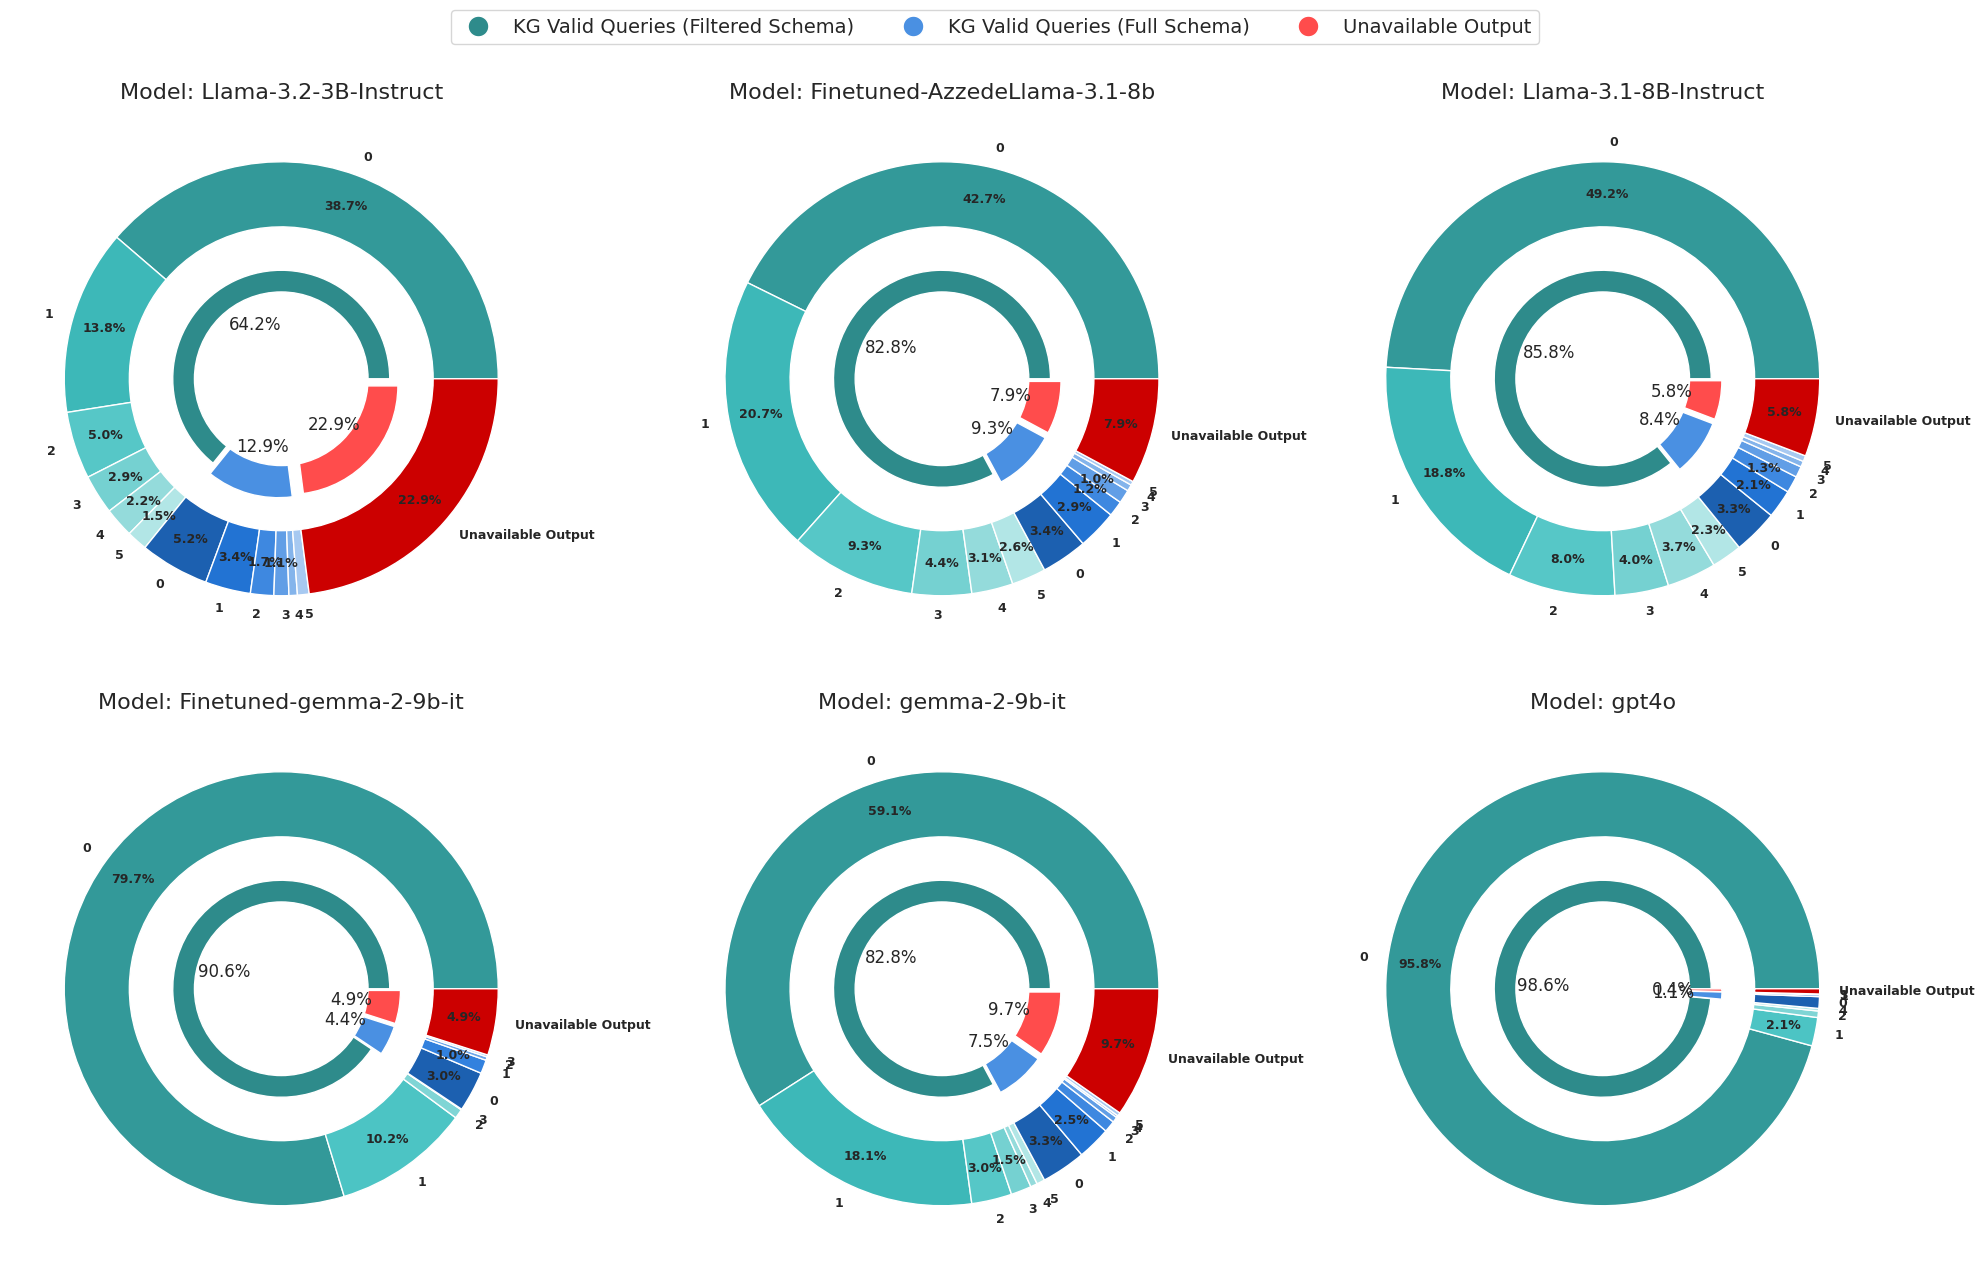

In [47]:
from matplotlib.cm import get_cmap
import colorsys
import numpy as np
import matplotlib.pyplot as plt

all_df_copy = all_df.copy()
all_df_copy['Iteration'] = all_df_copy['Iteration'].fillna('Unavailable Output')
all_df_copy['Iteration'] = all_df_copy['Iteration'].astype(str)
models = all_df_copy['Model'].unique()
num_models = len(models)

ncols = 3
nrows = int(np.ceil(num_models / ncols))
fig, axs = plt.subplots(nrows, ncols, figsize=(20, 13), subplot_kw=dict(aspect="equal"))
axs = axs.flatten() if num_models > 1 else [axs]

base_colors = ['#2E8B8B', '#4A90E2', '#FF4C4C']

def hex_to_rgb_fraction(hex_color):
    hex_color = hex_color.lstrip('#')
    return tuple(int(hex_color[i:i+2], 16)/255 for i in (0, 2, 4))

def autopct_format(pct):
    return f'{pct:.01f}%' if pct > 1 else ''

def clean_iteration_label(x):
    try:
        return str(int(float(x))) #+ ' Iter.'  # Convert numeric-looking strings like "2.0" → "2"
    except:
        return x  # Keep non-numeric ones like "Unavailable Output"



for ax, model in zip(axs, models):
    df = all_df_copy[all_df_copy['Model'] == model]
    group_totals = df.groupby('Group')['Value'].sum()
    group_labels = group_totals.index
    group_sizes = group_totals.values

    group_color_map = {g: base_colors[i % len(base_colors)] for i, g in enumerate(group_labels)}

    # Generate iteration colors as shades of group color
    iteration_colors = []
    for _, row in df.iterrows():
        base_rgb = hex_to_rgb_fraction(group_color_map[row['Group']])
        h, l, s = colorsys.rgb_to_hls(*base_rgb)
        group_iters = df[df['Group'] == row['Group']]['Iteration'].unique()
        iter_idx = np.where(group_iters == row['Iteration'])[0][0]
        lightness = 0.4 + 0.4 * (iter_idx / max(len(group_iters) - 1, 1))
        rgb = colorsys.hls_to_rgb(h, lightness, s)
        iteration_colors.append(rgb)

   # Outer pie explode: add gap **only before** slices where group changes (except very first slice)
    gap_size_outer = 0.05
    explode_outer = []
    prev_group = None
    for i, (_, row) in enumerate(df.iterrows()):
        if i == 0:
            explode_outer.append(0)  # no gap for first slice
        else:
            explode_outer.append(gap_size_outer if row['Group'] != prev_group else 0)
        prev_group = row['Group']

    # Inner pie explode: 0 for first group slice, gap for all others to separate groups
    gap_size_inner = 0.05
    explode_inner = [0] + [gap_size_inner] * (len(group_labels) - 1)


    # Outer pie (Iterations)
    wedges_outer, _, autotexts_outer = ax.pie(
        df['Value'],
        radius=1,
        labels = df['Iteration'].apply(clean_iteration_label),
        labeldistance=1.09,#None
        colors=iteration_colors,
        wedgeprops=dict(width=0.3, edgecolor='white'),
        autopct=autopct_format,
        pctdistance=0.85,
        textprops=dict(size=9, weight='bold'),
        # explode=explode_outer  # uncomment if explode desired
    )
    ## apply labels to wedges
    # labels = df['Iteration'].apply(clean_iteration_label)
    # for wedge, label in zip(wedges_outer, labels):
    #     angle = (wedge.theta2 + wedge.theta1) / 2.0
    #     x = math.cos(math.radians(angle))
    #     y = math.sin(math.radians(angle))

    #     ha = "left" if x >= 0 else "right"
    #     ax.text(x * 1.05, y * 1.05, label,
    #             horizontalalignment=ha,
    #             verticalalignment='center',
    #             rotation=angle if x >= 0 else angle + 180,
    #             rotation_mode='anchor',
    #             fontsize=9, weight='bold')
        
    # Inner pie (Groups)
    wedges_inner, _, autotexts_inner = ax.pie(
        group_sizes,
        radius=0.5,
        colors=[group_color_map[g] for g in group_labels],
        wedgeprops=dict(width=0.3, edgecolor='white'),
        autopct='%1.1f%%',
        pctdistance=0.55,
        textprops=dict(size=12,),# weight='bold'
        explode=explode_inner,
        #  shadow={'ox': -0.04, 'edgecolor': 'none', 'shade': 0.9}
    )
    
    # Donut center
    ax.add_artist(plt.Circle((0, 0), 0.4, fc='white'))
    ax.set_title(f'Model: {model}', fontsize=16)

# Disable unused axes
for ax in axs[num_models:]:
    ax.axis('off')

# Legend for groups (using last model's group_color_map)
handles = [plt.Line2D([0], [0], marker='o', color='w', label=group,
                      markerfacecolor=color, markersize=15)
           for group, color in group_color_map.items()]

fig.legend(handles=handles, loc='lower center', bbox_to_anchor=(0.5, 1), ncol=len(group_color_map), fontsize=14)
plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()

In [34]:
df

,Group,Iteration,Value,Model
61,KG Valid Queries (Filtered Schema),0.0,1987,gpt4o
62,KG Valid Queries (Filtered Schema),1.0,44,gpt4o
63,KG Valid Queries (Filtered Schema),2.0,10,gpt4o
64,KG Valid Queries (Filtered Schema),4.0,4,gpt4o
65,KG Valid Queries (Full Schema),0.0,18,gpt4o
66,KG Valid Queries (Full Schema),1.0,3,gpt4o
67,KG Valid Queries (Full Schema),3.0,1,gpt4o
68,Unavailable Output,Unavailable Output,8,gpt4o


# Detailed overview

In [17]:
def extract_and_plot(models_dict, extract_dfs_func, max_cols=3, figsize=(15, 5)):
    """
    Extract data for multiple models and plot horizontal bar charts for each.
    
    Parameters:
    - models_dict: A dictionary with keys the model names and the dfs with the calculated metrics
    - extract_dfs_func: function(path) returning (kg_valid_queries_df, unavailable_output_df, 
                                               kg_valid_queries_with_full_schema_df, kg_valid_queries_with_filtered_schema_df)
    - max_cols: maximum number of columns in subplot grid
    - figsize: size of figure, width will scale with columns
    
    Supports any number of models.
    """
    all_values_orig, all_values_pass, all_labels, all_thresholds, all_names = [], [], [], [], []

    models = models_dict.keys()

    for model_name in models_dict:
        df = models_dict[model_name]
        kg_valid_queries_df, unavailable_output_df, kg_valid_queries_with_full_schema_df, kg_valid_queries_with_filtered_schema_df = extract_dfs_func(df)
        
        # Original counts
        kg_valid_queries = len(kg_valid_queries_df)
        kg_valid_queries_with_full_schema = len(kg_valid_queries_with_full_schema_df)
        kg_valid_queries_with_filtered_schema = kg_valid_queries - kg_valid_queries_with_full_schema
        unavailable_output = len(unavailable_output_df)
        threshold = len(df)

        # Filtered counts where df['pass'] == True
        kg_valid_queries_pass = len(kg_valid_queries_df[kg_valid_queries_df['Pass@1 Output']==True])
        kg_valid_queries_with_full_schema_pass = len(kg_valid_queries_with_full_schema_df[kg_valid_queries_with_full_schema_df['Pass@1 Output']==True])
        kg_valid_queries_with_filtered_schema_pass = len(kg_valid_queries_with_filtered_schema_df[kg_valid_queries_with_filtered_schema_df['Pass@1 Output']==True])
        unavailable_output_pass = 0
        
        # Values for original bars and pass-filtered bars
        values_orig = [unavailable_output, kg_valid_queries, kg_valid_queries_with_full_schema, kg_valid_queries_with_filtered_schema]
        values_pass = [unavailable_output_pass, kg_valid_queries_pass, kg_valid_queries_with_full_schema_pass, kg_valid_queries_with_filtered_schema_pass]
        labels = ['Unavailable Output', 'KG Valid Queries', 'KG Valid Queries with Full Schema', 'KG Valid Queries with Filtered Schema']
        
        all_values_orig.append(values_orig)
        all_values_pass.append(values_pass)
        all_labels.append(labels)
        all_thresholds.append(threshold)
        all_names.append(model_name)
    
    n_plots = len(models)
    n_cols = min(max_cols, n_plots)
    n_rows = math.ceil(n_plots / n_cols)
    fig_width = figsize[0] * n_cols / max_cols
    fig_height = figsize[1] * n_rows
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(fig_width, fig_height), squeeze=False)
    axes_flat = axes.flatten()
    
    def plot_barh(ax, values_orig, values_pass, labels, threshold, model_name):
        # Bar width and positions for grouped bars
        y_pos = np.arange(len(labels))
        bar_height = 0.35
        
        # Plot original bars
        ax.barh(y_pos - bar_height/2, values_orig, height=bar_height, color='skyblue', label='KG Valid')
        # Plot pass==True bars next to original
        ax.barh(y_pos + bar_height/2, values_pass, height=bar_height, color='lightgreen', label='Pass=True')
        
        # Add values and percentages text
        for i, (val_o, val_p) in enumerate(zip(values_orig, values_pass)):
            pct_o = (val_o / threshold) * 100 if threshold > 0 else 0
            pct_p = (val_p / threshold) * 100 if threshold > 0 else 0
            ax.text(val_o + 0.5, i - bar_height/2, f'{val_o} ({pct_o:.0f}%)', va='center', fontsize=9)
            ax.text(val_p + 0.5, i + bar_height/2, f'{val_p} ({pct_p:.0f}%)', va='center', fontsize=9)
        
        ax.set_yticks(y_pos)
        ax.set_yticklabels(labels)
        ax.axvline(x=threshold, color='red', linestyle='--', label='Threshold')
        ax.set_xlabel('Value')
        ax.set_title(model_name.title())
        ax.legend()
        ax.set_xticks(np.arange(0, threshold + 5, max(1, threshold // 10) if threshold > 10 else 1))
    
    for i in range(n_plots):
        plot_barh(axes_flat[i], all_values_orig[i], all_values_pass[i], all_labels[i], all_thresholds[i], all_names[i])
    
    # Hide unused axes if any
    for j in range(n_plots, len(axes_flat)):
        axes_flat[j].axis('off')
    
    plt.tight_layout(w_pad=4, h_pad=4)
    plt.show()


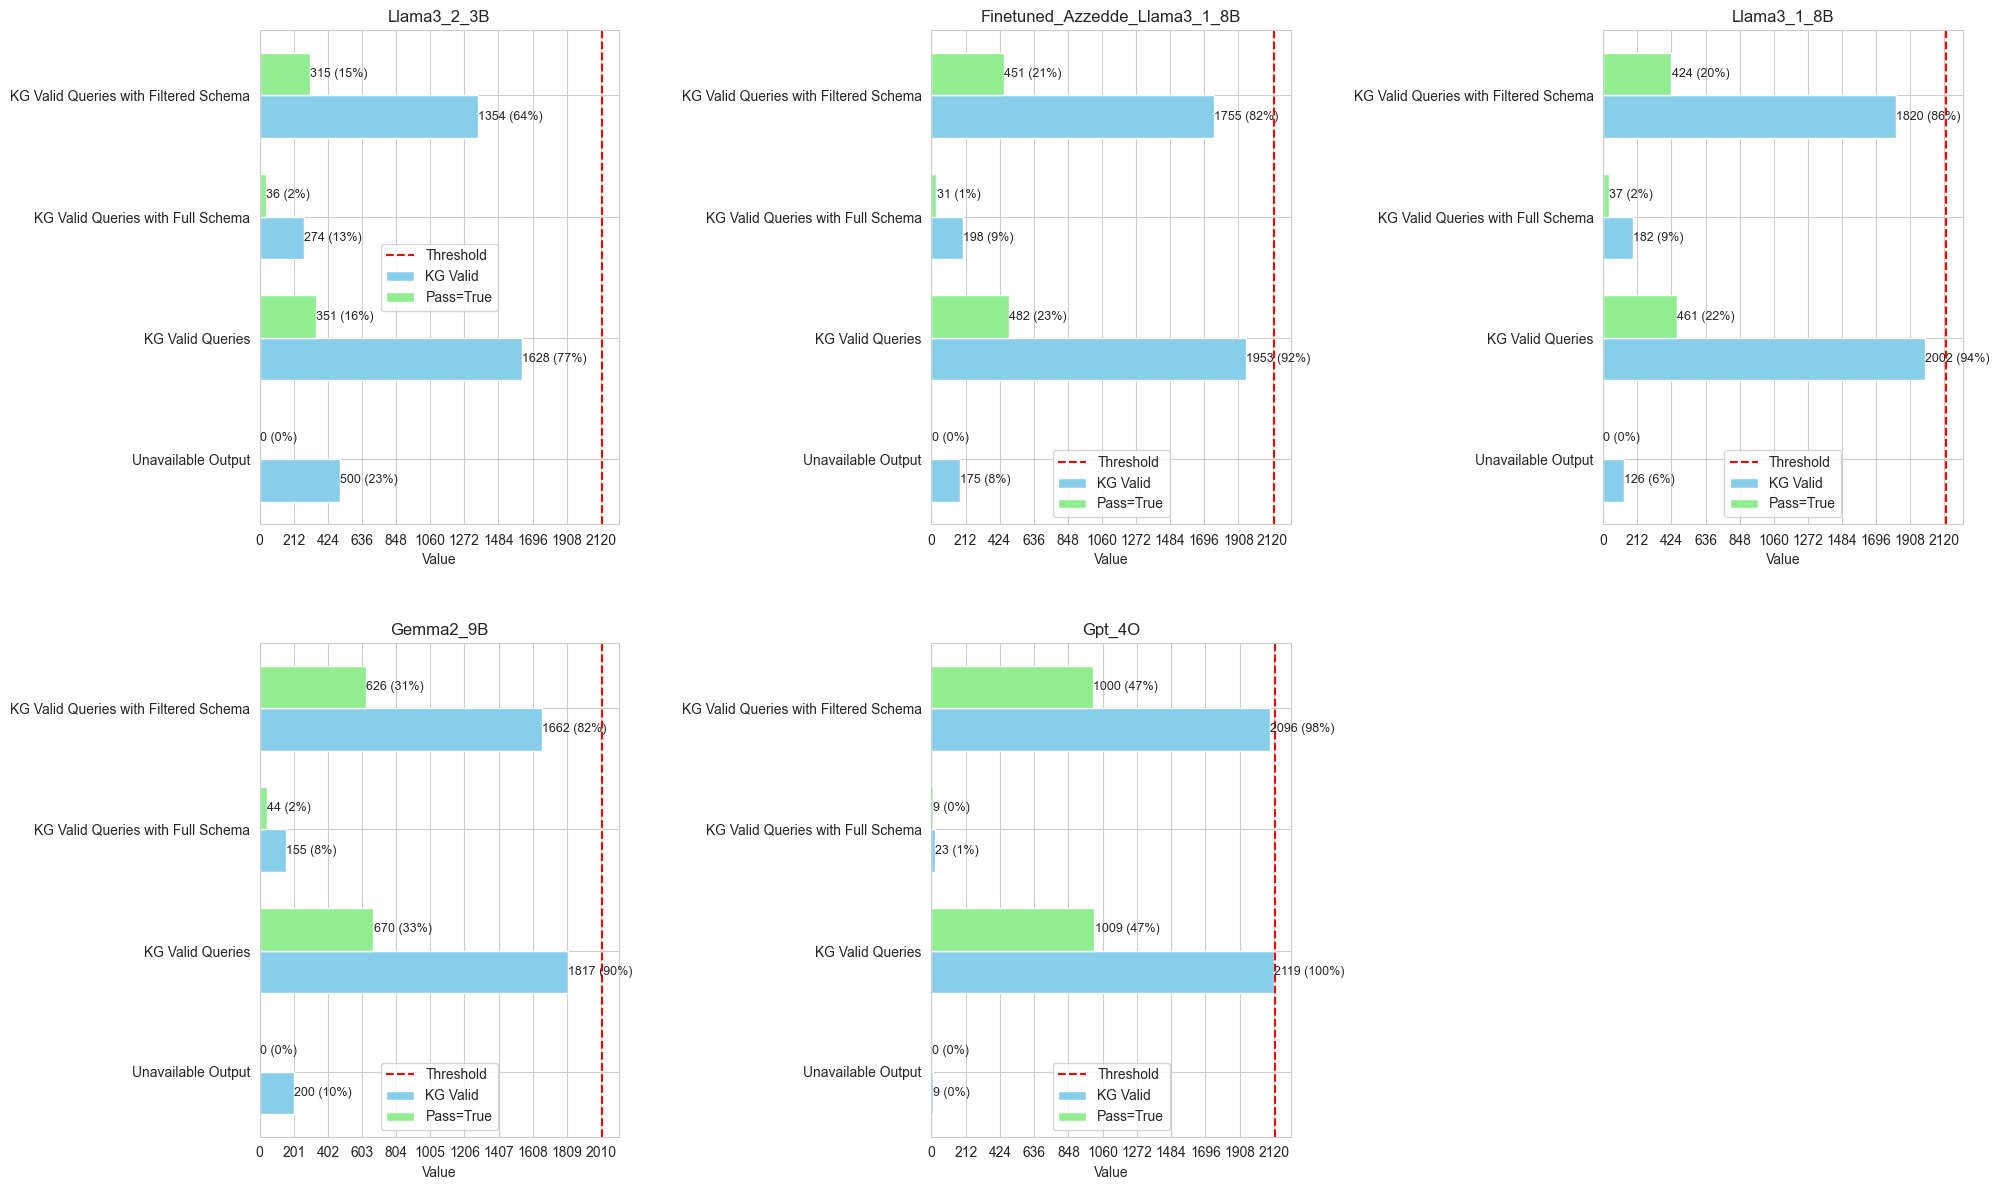

In [18]:
extract_and_plot(models_dict= extended_dfs_dict,extract_dfs_func = extract_dfs,max_cols=3,figsize = (20,6))

# Errors

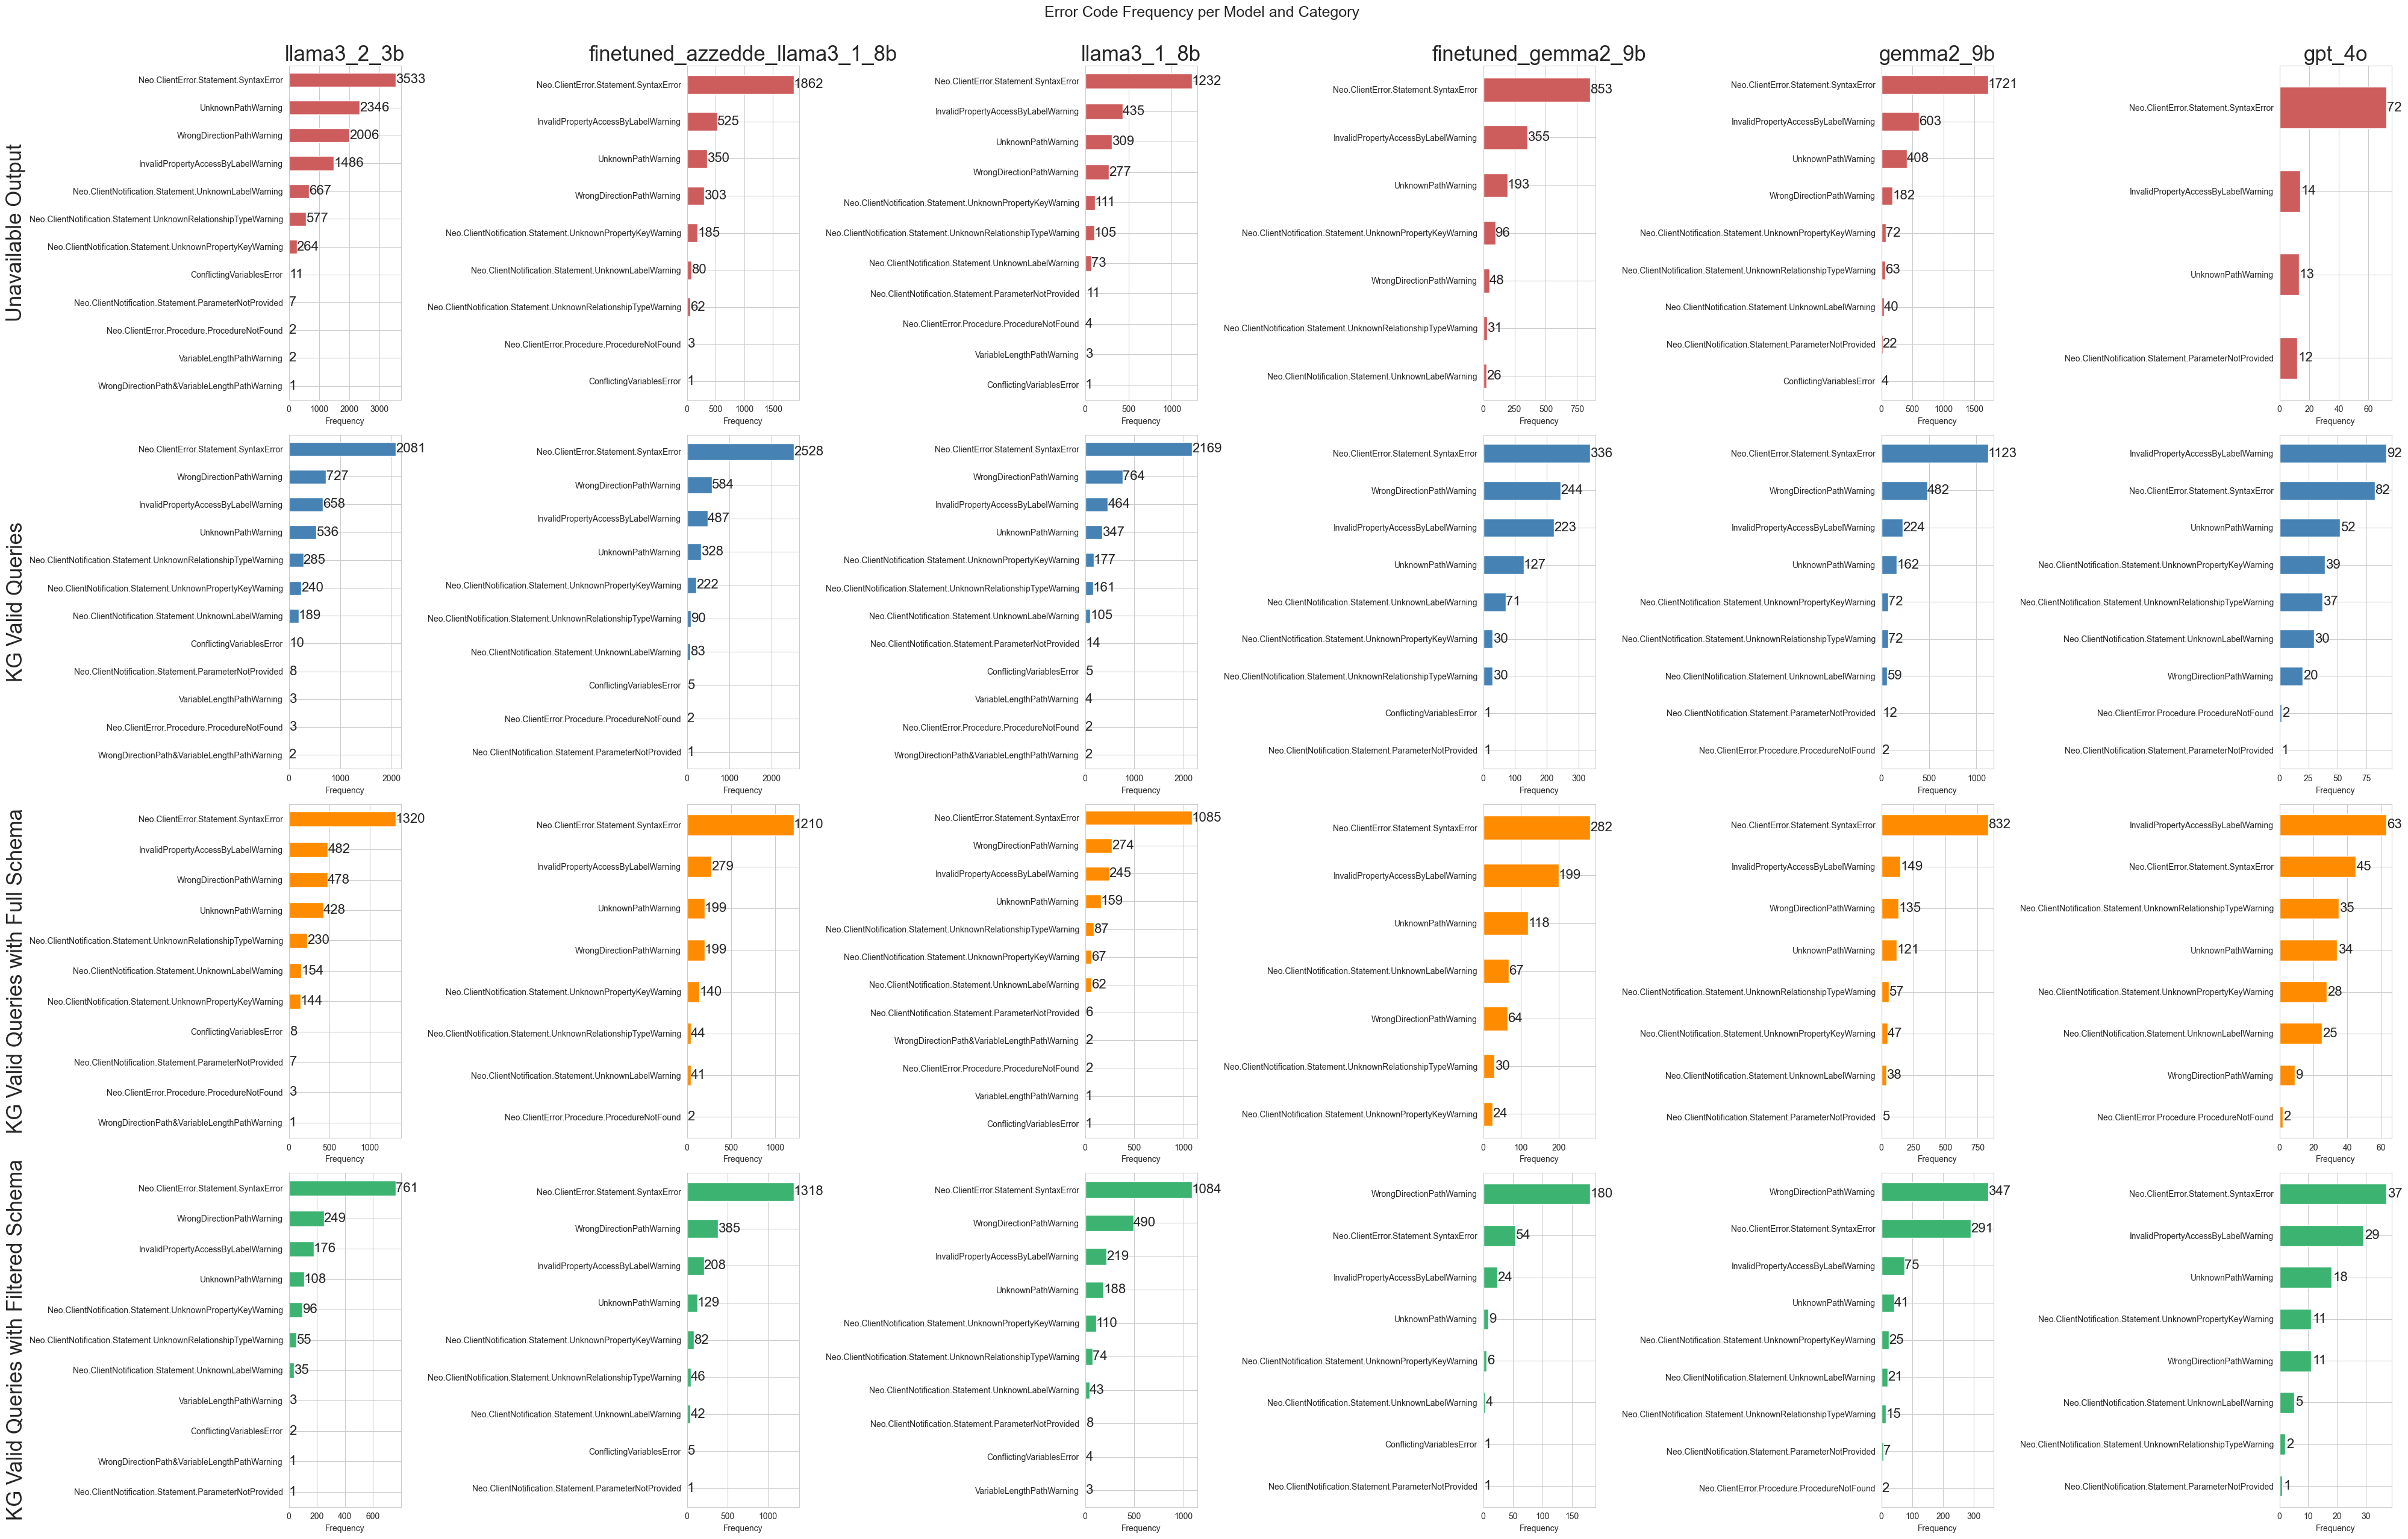

In [113]:
models = list(extended_dfs_dict.keys())
num_models = len(models)
num_labels = 4  # Your 4 categories/labels

fig, axes = plt.subplots(num_labels, num_models, figsize=(40,25))
# no sharey parameter, so each subplot has its own y-axis
# share y-axis across rows to compare error codes better

# If only one model, axes might be 1D, so make it always 2D for convenience:
if num_models == 1:
    axes = axes[:, None]

labels = ['Unavailable Output', 'KG Valid Queries', 'KG Valid Queries with Full Schema', 'KG Valid Queries with Filtered Schema']
colors = ['indianred', 'steelblue', 'darkorange', 'mediumseagreen']

for col, model_name in enumerate(models):
    kg_valid_queries_df, unavailable_output_df, kg_valid_queries_with_full_schema_df, kg_valid_queries_with_filtered_schema_df = extract_dfs(extended_dfs_dict[model_name])
    dfs = [unavailable_output_df, kg_valid_queries_df, kg_valid_queries_with_full_schema_df, kg_valid_queries_with_filtered_schema_df]

    for row, (df, label, color) in enumerate(zip(dfs, labels, colors)):
        ax = axes[row, col]

        error_counts = pd.Series([err for sublist in df.flattened_cypher_errors_history for err in sublist]).value_counts()
        error_counts.plot(kind='barh', color=color, ax=ax)

        for j, (error_type, count) in enumerate(error_counts.items()):
            ax.text(count + 0.5, j, str(count), va='center', fontsize=16)

        if col == 0:
            ax.set_ylabel(label, fontsize=25)
        else:
            ax.set_ylabel('')  # Hide y-labels for non-left columns

        if row == 0:
            ax.set_title(model_name, fontsize=25)

        ax.set_xlabel('Frequency')
        ax.invert_yaxis()


plt.tight_layout()
plt.suptitle('Error Code Frequency per Model and Category', fontsize=18, y=1.02)
plt.show()


# WordCloud/Tree maps

In [114]:
!pip install wordcloud

In [115]:
from wordcloud import WordCloud, STOPWORDS
import matplotlib.pyplot as plt

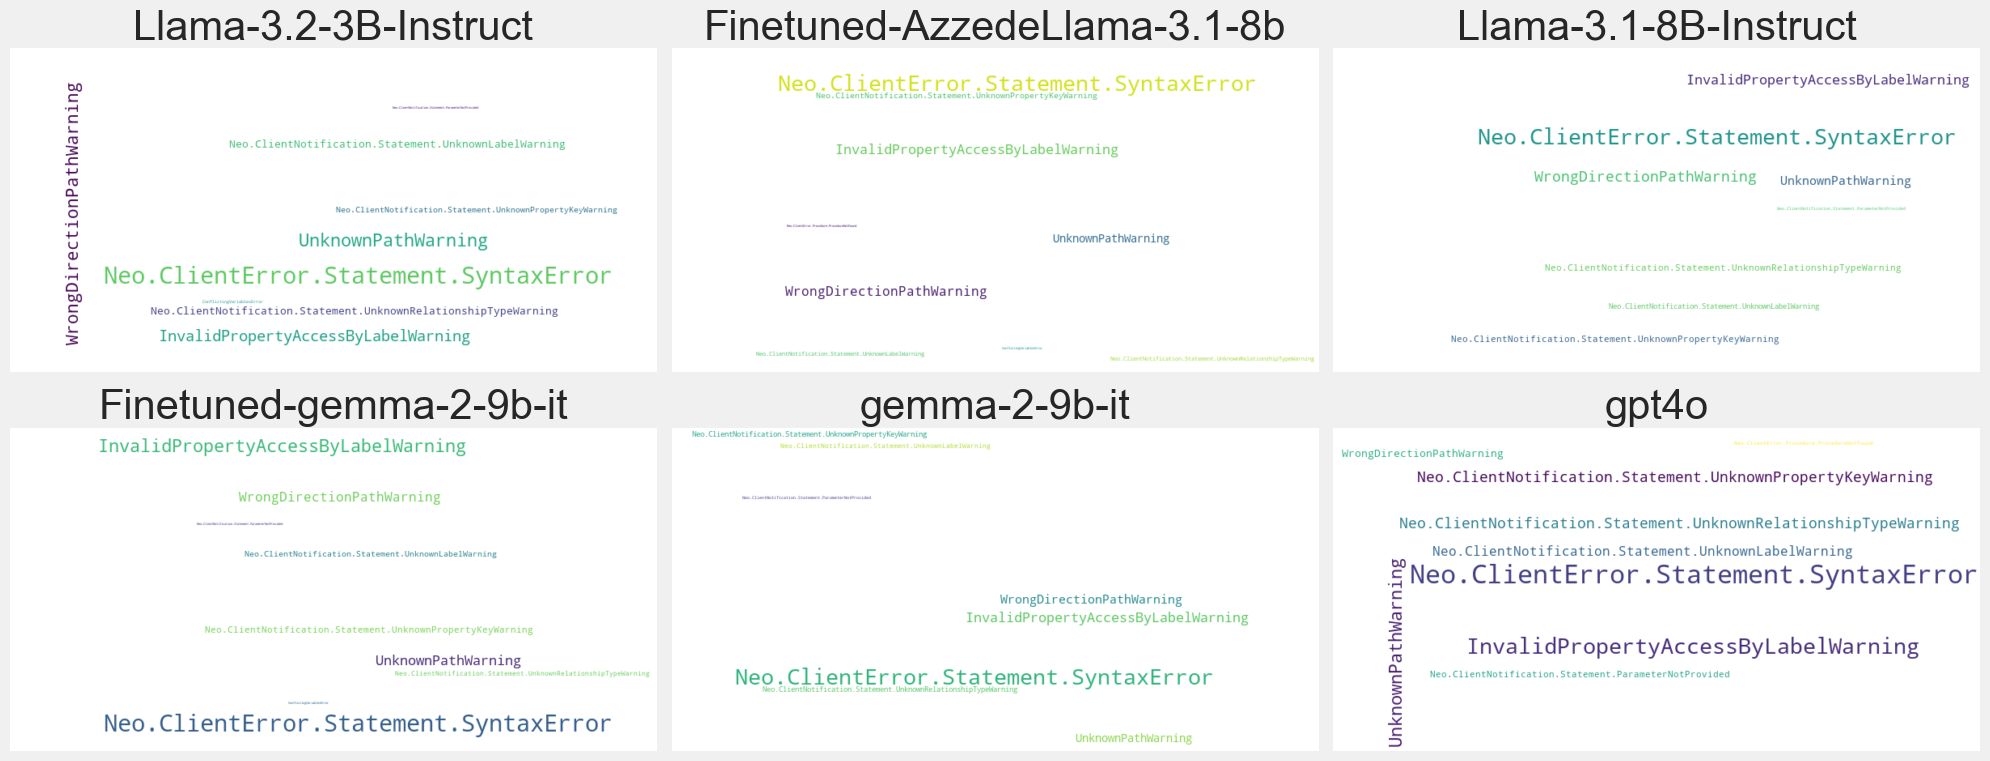

In [116]:
# Suppose extended_dfs_dict is your dict: { model_name: dataframe, ... }
models = list(extended_dfs_dict.keys())
n_models = len(models)

# Grid dims (3 cols, adjust rows to fit all models)
ncols = 3
nrows = int(np.ceil(n_models / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(20, 8))
axes_flat = axes.flatten()
fig.patch.set_facecolor('#f0f0f0')


for idx, model_name in enumerate(models):
    ax = axes_flat[idx]
    df = extended_dfs_dict[model_name]

    # Build your frequency dict of error codes
    error_counts = pd.Series([err for sublist in  df.flattened_cypher_errors_history for err in sublist]).value_counts()
    freqs = error_counts.to_dict()

    # Configure & generate the WordCloud
    wc = WordCloud(
        width=800,
        height=400,
        background_color='white',
        contour_color='steelblue'   # optional outline
    ).generate_from_frequencies(freqs)

    # Draw onto the ax
    ax.imshow(wc.to_array(), interpolation='bilinear')
    ax.set_axis_off()
    ax.set_title(models_mapping[model_name], fontsize=30)

# Turn off any remaining empty subplots
for ax in axes_flat[n_models:]:
    ax.axis('off')

# plt.suptitle('Error Code Frequency per Model', fontsize=18, y=1.02)
plt.tight_layout()
plt.show()

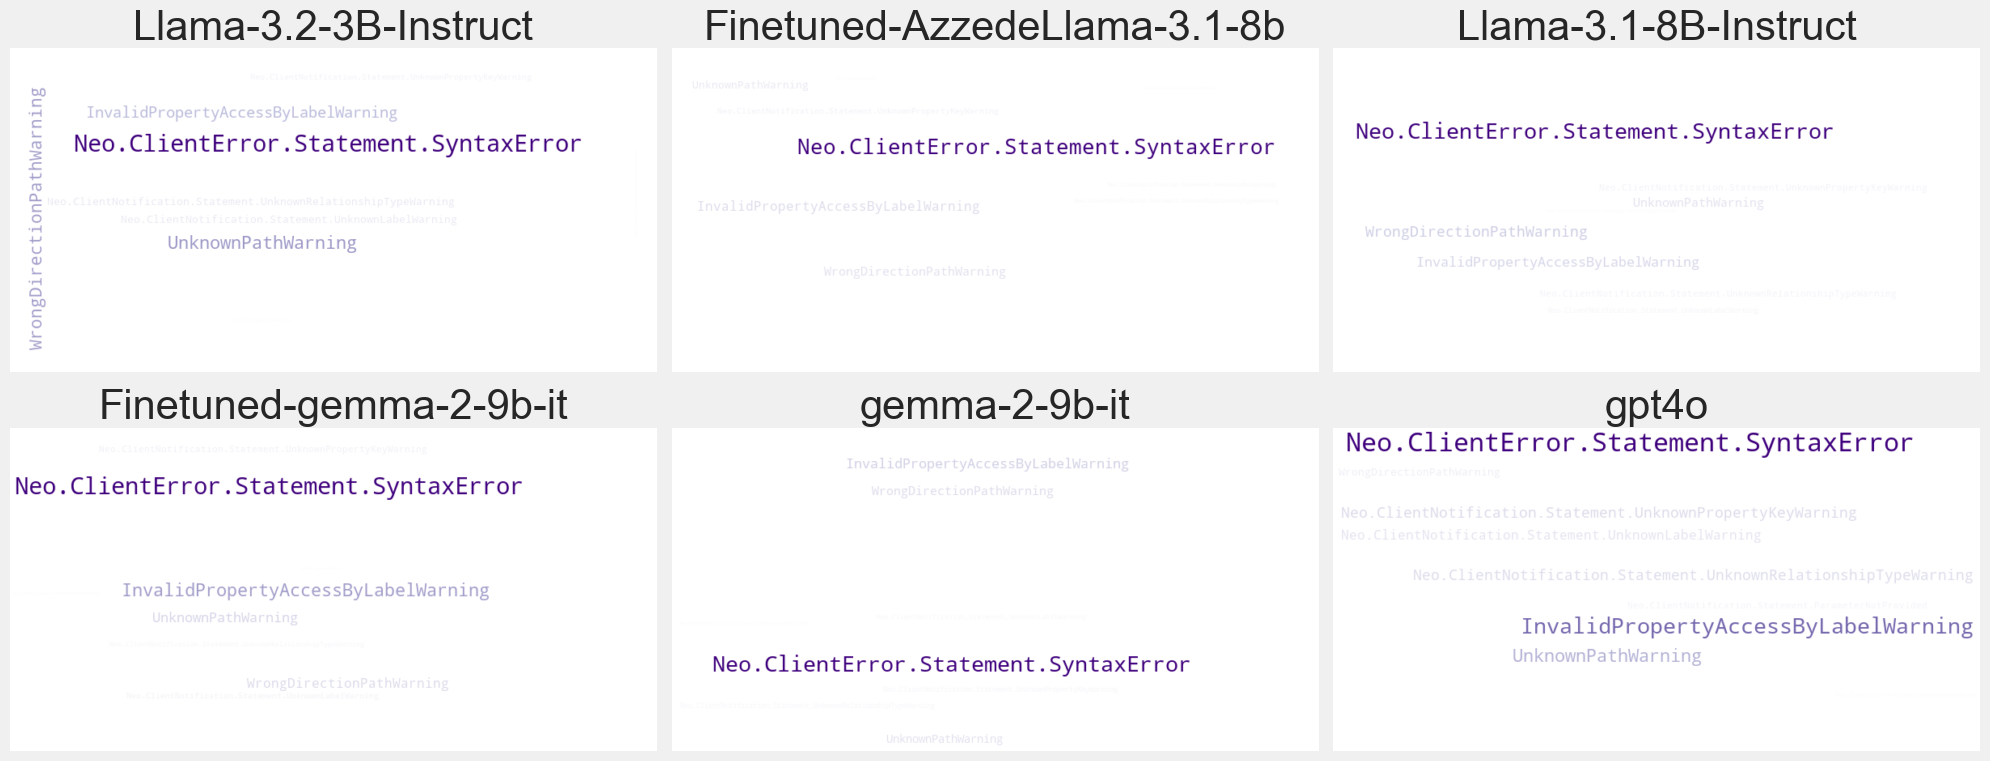

In [117]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt
import numpy as np

models = list(extended_dfs_dict.keys())
n_models = len(models)

ncols = 3
nrows = int(np.ceil(n_models / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(20, 8))
axes_flat = axes.flatten()
fig.patch.set_facecolor('#f0f0f0')

for idx, model_name in enumerate(models):
    ax = axes_flat[idx]
    df = extended_dfs_dict[model_name]

    # Build your frequency dict of error codes
    error_counts = pd.Series([err for sublist in  df.flattened_cypher_errors_history for err in sublist]).value_counts()
    freqs = error_counts.to_dict()

    # Normalize frequencies for color mapping
    freq_values = np.array(list(freqs.values()))
    min_freq, max_freq = freq_values.min(), freq_values.max()
    freq_norm_dict = {word: (freq - min_freq) / (max_freq - min_freq + 1e-9) for word, freq in freqs.items()}

    # Choose a matplotlib colormap (e.g., Reds reversed so highest freq = darkest red)
    cmap = plt.colormaps.get_cmap('Purples')

    def color_func(word, font_size, position, orientation, random_state=None, **kwargs):
        norm_val = freq_norm_dict.get(word, 0)
        r, g, b, a = cmap(norm_val)
        return f"rgb({int(r*255)}, {int(g*255)}, {int(b*255)})"

    # Generate WordCloud with custom color_func
    wc = WordCloud(
        width=800,
        height=400,
        background_color='white',
        contour_color='steelblue',
        color_func=color_func
    ).generate_from_frequencies(freqs)

    # Draw onto the ax
    ax.imshow(wc.to_array(), interpolation='bilinear')
    ax.set_axis_off()
    ax.set_title(models_mapping[model_name], fontsize=30)

# Turn off any remaining empty subplots
for ax in axes_flat[n_models:]:
    ax.axis('off')

plt.tight_layout()
plt.show()


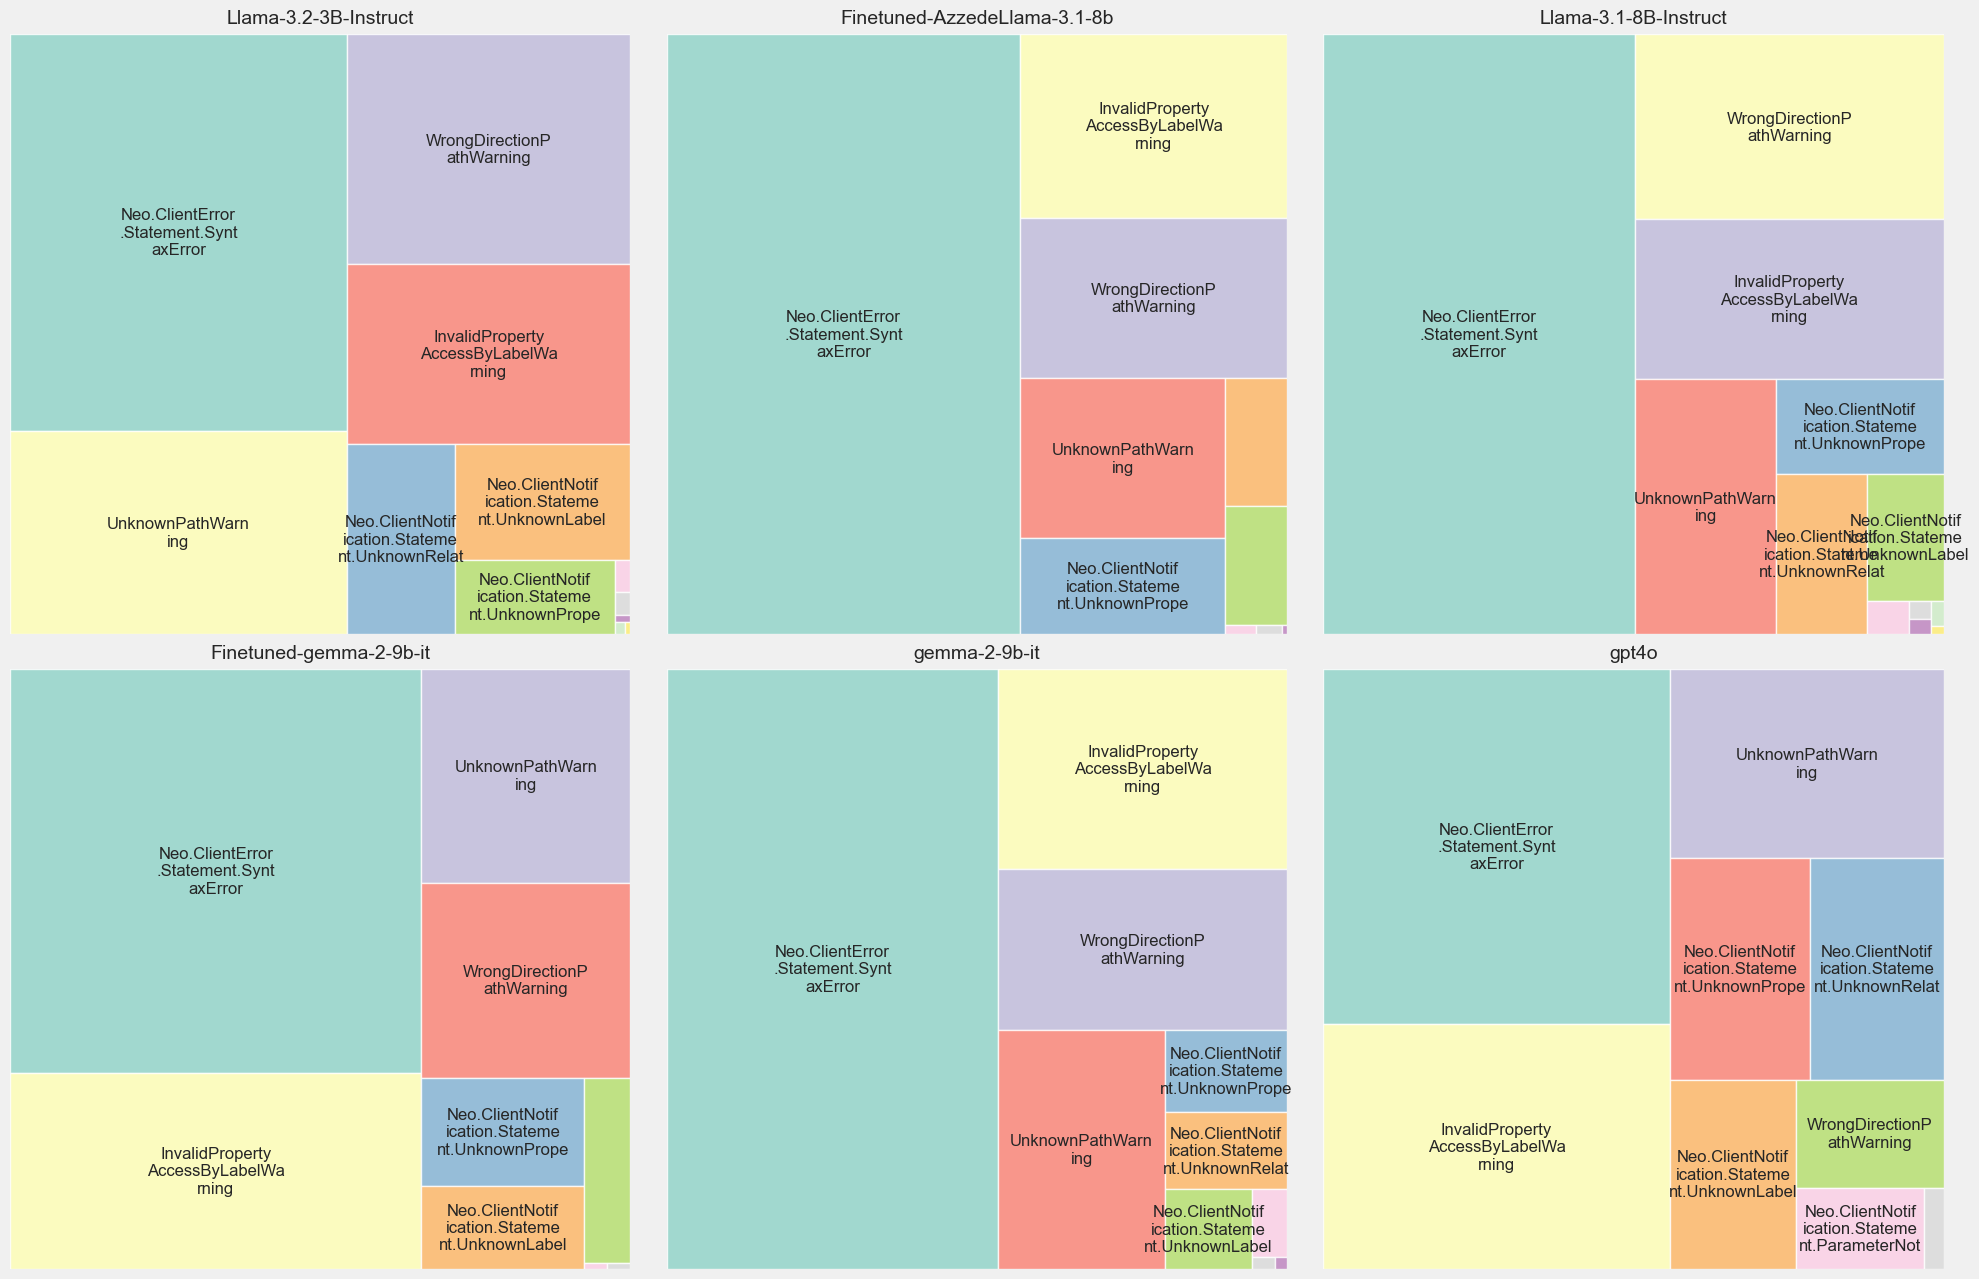

In [119]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import squarify
import textwrap
from matplotlib.patches import Patch

models    = list(extended_dfs_dict.keys())
n_models  = len(models)
ncols     = 3
nrows     = int(np.ceil(n_models / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(20, 15))
axes_flat = axes.flatten()
fig.patch.set_facecolor('#f0f0f0')

def wrap_label(lbl, width=15):
    return "\n".join(textwrap.wrap(lbl, width=width))

def draw_wrapped_text(ax, x, y, width, height, text, fontsize=12, max_lines=3):
    # Wrap the text to fit max width (number of chars can be tuned)
    wrapped = textwrap.wrap(text, width=15)
    wrapped = wrapped[:max_lines]  # limit max lines
    wrapped_text = "\n".join(wrapped)
    # Draw centered text inside rectangle
    ax.text(
        x + width / 2,
        y + height / 2,
        wrapped_text,
        ha='center',
        va='center',
        fontsize=fontsize,
        wrap=True
    )

# Prepare combined error counts across all models for the legend
all_error_counts = pd.Series(dtype=int)
for model_name in models:
    df = extended_dfs_dict[model_name]
    error_counts = pd.Series([err for sub in  df.flattened_cypher_errors_history for err in sub]).value_counts()
    all_error_counts = all_error_counts.add(error_counts, fill_value=0)

# Top N + Other for the combined legend
N = 20
common = all_error_counts.nlargest(N)
labels = common.index.tolist()
sizes = common.values.tolist()
other = all_error_counts.sum() - sum(sizes)
if other > 0:
    labels.append("Other")
    sizes.append(other)

# Colors and wrapped labels for legend
cmap = plt.get_cmap('Set3')
colors = [cmap(i) for i in range(len(sizes))]
legend_labels = [wrap_label(lbl) for lbl in labels]

MIN_SIZE = 10  # minimum width and height to show text

for idx, model_name in enumerate(models):
    ax = axes_flat[idx]
    df = extended_dfs_dict[model_name]

    # Build frequency dict for this model
    error_counts = pd.Series([err for sub in  df.flattened_cypher_errors_history for err in sub]).value_counts()

    # Top N + Other
    common_model = error_counts.nlargest(N)
    labels_model = common_model.index.tolist()
    sizes_model  = common_model.values.tolist()
    other_model = error_counts.sum() - sum(sizes_model)
    if other_model > 0:
        labels_model.append("Other")
        sizes_model.append(other_model)

    # Normalize sizes to fit into 100x100 area
    norm_sizes = squarify.normalize_sizes(sizes_model, 100, 100)
    rects = squarify.squarify(norm_sizes, 0, 0, 100, 100)

    # Clear axis and draw treemap manually with wrapped text
    ax.clear()
    ax.axis('off')
    ax.set_title(models_mapping.get(model_name, model_name), fontsize=14, pad=8)

    for i, rect in enumerate(rects):
        x, y, dx, dy = rect['x'], rect['y'], rect['dx'], rect['dy']
        color = colors[i] if i < len(colors) else (0.8, 0.8, 0.8)  # fallback color

        ax.add_patch(plt.Rectangle((x, y), dx, dy, facecolor=color, edgecolor='white', linewidth=1, alpha=0.8))

        # Show text only if tile is big enough
        if dx > MIN_SIZE and dy > MIN_SIZE:
            draw_wrapped_text(ax, x, y, dx, dy, labels_model[i])

    ax.set_xlim(0, 100)
    ax.set_ylim(0, 100)
    ax.invert_yaxis()

# Turn off any extra axes
for ax in axes_flat[n_models:]:
    ax.axis('off')

plt.tight_layout()
plt.subplots_adjust(bottom=0.15)  # make room for legend
plt.show()
